<a href="https://colab.research.google.com/github/garvcodes/torchleet/blob/main/torch/easy/cnn/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- torchleet:colab -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Exorust/TorchLeet/blob/main/torch/easy/cnn/CNN.ipynb)

Check your work: `!pip install torchleet` then `from torchleet import check; check("cnn", ...)`


# Problem: Implement a CNN for CIFAR-10 in PyTorch

### Problem Statement
You are tasked with implementing a **Convolutional Neural Network (CNN)** for image classification on the **CIFAR-10** dataset using PyTorch. The model should contain convolutional layers for feature extraction, pooling layers for downsampling, and fully connected layers for classification. Your goal is to complete the CNN model by defining the necessary layers and implementing the forward pass.

### Requirements
1. **Define the CNN Model**:
   - Add **convolutional layers** for feature extraction.
   - Add **pooling layers** to reduce the spatial dimensions.
   - Add **fully connected layers** to output class predictions.
   - The model should be capable of processing input images of size `(32x32x3)` as in the CIFAR-10 dataset.

### Constraints
- The CNN should be designed with multiple convolutional and pooling layers followed by fully connected layers.
- Ensure the model is compatible with the CIFAR-10 dataset, which contains 10 classes.


<details>
  <summary>💡 Hint</summary>
  Add the convolutional (conv1, conv2), pooling (pool), and fully connected layers (fc1, fc2) in CNNModel.__init__.
  <br>
  Implement the forward pass to process inputs through these layers.
</details>

In [38]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

In [11]:
# Load CIFAR-10 dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)

Dataset length: 50000
Sample Shape:  torch.Size([3, 32, 32])
Sample Label:  6


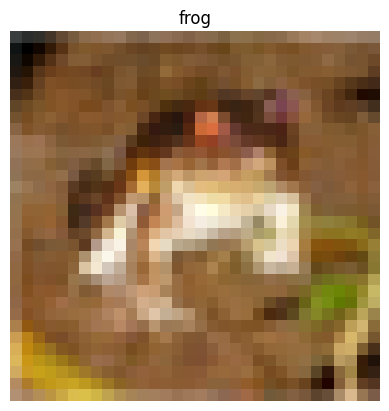

In [28]:
print("Dataset length:", len(train_dataset))
sample, target = train_dataset[0]
print("Sample Shape: ", sample.shape)
print("Sample Label: ", target)

import matplotlib.pyplot as plt
# Display the image.

sample = sample * 0.5 + 0.5
sample = sample.permute(1, 2, 0)

plt.imshow(sample)

# Show the corresponding class name.
plt.title(train_dataset.classes[target])

# Hide the coordinate axes.
plt.axis("off")

# Render the plot.
plt.show()

In [52]:
# Define the CNN Model
# TODO: Add convolutional, pooling, and fully connected layers
class CNNModel(nn.Module):
    def __init__(self):
        ...
        super().__init__()

        #first shape (3, 32, 32)

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1,
        )

        #second shape (16, 32, 32)

        self.pool1 = nn.MaxPool2d(
            kernel_size=2,
            stride = 2,
            padding = 0
        )

        #third shape (16, 16, 16)

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            stride=1,
            padding=1,
        )

        #fourth shape (32, 16, 16)

        self.pool2 = nn.MaxPool2d(
            kernel_size=2,
            stride = 2,
            padding = 0
        )

        #fourth shape (32, 8, 8)

        self.fc1 = nn.Linear(
          in_features=2048,
          out_features=128
          )

        # Convert 128 features into 10 class scores.
        self.fc2 = nn.Linear(
          in_features=128,
          out_features=10
        )




    def forward(self, x):
        post_conv1 = F.relu(self.conv1(x))
        post_pool1 = self.pool1(post_conv1)
        post_conv2 = F.relu(self.conv2(post_pool1))
        post_pool2 = self.pool2(post_conv2)

        last = torch.flatten(post_pool2, start_dim=1)
        last = F.relu(self.fc1(last))

# Produce the final 10 class logits.
        last = self.fc2(last)

        return last


In [53]:
# Initialize the model, loss function, and optimizer
model = CNNModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
epochs = 10
for epoch in range(epochs):
    for images, labels in train_loader:
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [1/10], Loss: 1.0675
Epoch [2/10], Loss: 1.4067
Epoch [3/10], Loss: 1.4625
Epoch [4/10], Loss: 0.9320
Epoch [5/10], Loss: 0.6880
Epoch [6/10], Loss: 0.9634
Epoch [7/10], Loss: 0.4767
Epoch [8/10], Loss: 0.5497
Epoch [9/10], Loss: 0.6728
Epoch [10/10], Loss: 0.6819


In [ ]:
# Evaluate on the test set
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Test Accuracy: {100 * correct / total:.2f}%")